In [11]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os

In [2]:
def read_hist_out(path, numeric_first_col=True):
    """
    Read a G4SEE histogram ``.out`` file into a DataFrame.

    The first line holds the column labels (e.g. ``Edep  Counts``).
    Subsequent lines hold the data. The first data column may contain the
    special strings ``underflow`` and ``overflow`` alongside numeric bin
    values.

    Parameters
    ----------
    path : str
        Path to the ``.out`` file.
    numeric_first_col : bool, optional
        If True (default), the first column is converted to a float where
        possible; ``underflow``/``overflow`` entries become ``np.nan``.
        If False, the first column is kept as strings.

    Returns
    -------
    pd.DataFrame
        DataFrame using the header labels as column names.
    """
    df = pd.read_csv(
        path,
        sep=r"\s+",
        skipinitialspace=True,
        engine="python",
    )

    if numeric_first_col:
        first = df.columns[0]
        df[first] = pd.to_numeric(df[first], errors="coerce")

    return df

In [7]:
def edit_sv_geometry(mac_path, width, thick, width_unit=None, thick_unit=None, inplace=True):
    """
    Edit the ``/SEE/geometry/SV`` line in a G4SEE ``.mac`` file.

    Only the WIDTH (2 entries) and THICK (1 entry) values are changed.
    POSITION and BIAS are left untouched.

    The SV line has the token layout::

        /SEE/geometry/SV  pos_x pos_y pos_z pos_unit  width_x width_y width_unit  thick thick_unit  bias

    Parameters
    ----------
    mac_path : str
        Path to the ``.mac`` file.
    width : sequence of 2 numbers
        New WIDTH values (x, y).
    thick : number
        New THICK value.
    width_unit : str, optional
        New WIDTH unit. If None, the existing unit is kept.
    thick_unit : str, optional
        New THICK unit. If None, the existing unit is kept.
    inplace : bool, optional
        If True (default), overwrite the file. If False, return the new
        file content as a string instead.

    Returns
    -------
    str or None
        The new file content when ``inplace`` is False, else None.

    Example
    -------
    >>> edit_sv_geometry("SRAM.mac", width=(800, 1000), thick=800)
    """
    if len(width) != 2:
        raise ValueError("width must be a sequence of exactly 2 values (x, y).")

    with open(mac_path, "r") as f:
        lines = f.readlines()

    new_lines = []
    edited = False
    for raw_line in lines:
        # Split off any trailing comment so it is preserved.
        comment = ""
        body = raw_line
        if "#" in raw_line:
            idx = raw_line.index("#")
            comment = raw_line[idx:]
            body = raw_line[:idx]
        body_no_nl = body.rstrip("\n")
        nl = "\n" if raw_line.endswith("\n") else ""
        stripped = body_no_nl.strip()

        if stripped.startswith("/SEE/geometry/SV"):
            tokens = stripped.split()
            # 0:cmd 1:px 2:py 3:pz 4:pos_unit 5:wx 6:wy 7:width_unit 8:thick 9:thick_unit 10:bias
            if len(tokens) < 11:
                raise ValueError(
                    f"Unexpected SV line format (expected 11 tokens, got {len(tokens)}): {stripped!r}"
                )
            tokens[5] = str(width[0])
            tokens[6] = str(width[1])
            if width_unit is not None:
                tokens[7] = width_unit
            tokens[8] = str(thick)
            if thick_unit is not None:
                tokens[9] = thick_unit
            new_line = " ".join(tokens)
            if comment:
                new_line += "   " + comment
            new_lines.append(new_line + nl)
            edited = True
        else:
            new_lines.append(body_no_nl + comment + nl)

    if not edited:
        raise ValueError(f"No '/SEE/geometry/SV' line found in {mac_path}.")

    content = "".join(new_lines)
    if inplace:
        with open(mac_path, "w") as f:
            f.write(content)
    return content

In [4]:
def edit_bulk_geometry(mac_path, width, thick, width_unit=None, thick_unit=None, inplace=True):
    """
    Edit the ``/SEE/geometry/Bulk`` line in a G4SEE ``.mac`` file.

    Only the WIDTH (1 entry) and THICK (1 entry) values are changed.
    The material and BIAS are left untouched.

    The Bulk line has the token layout::

        /SEE/geometry/Bulk material width width_unit thick thick_unit bias

    Parameters
    ----------
    mac_path : str
        Path to the ``.mac`` file.
    width : number
        New WIDTH value.
    thick : number
        New THICK value.
    width_unit : str, optional
        New WIDTH unit. If None, the existing unit is kept.
    thick_unit : str, optional
        New THICK unit. If None, the existing unit is kept.
    inplace : bool, optional
        If True (default), overwrite the file. If False, return the new
        file content as a string instead.

    Returns
    -------
    str or None
        The new file content when ``inplace`` is False, else None.

    Example
    -------
    >>> edit_bulk_geometry("SRAM.mac", width=8, thick=2)
    """
    with open(mac_path, "r") as f:
        lines = f.readlines()

    new_lines = []
    edited = False
    for raw_line in lines:
        comment = ""
        body = raw_line
        if "#" in raw_line:
            idx = raw_line.index("#")
            comment = raw_line[idx:]
            body = raw_line[:idx]
        body_no_nl = body.rstrip("\n")
        nl = "\n" if raw_line.endswith("\n") else ""
        stripped = body_no_nl.strip()

        if stripped.split()[:1] == ["/SEE/geometry/Bulk"]:
            tokens = stripped.split()
            # 0:cmd 1:material 2:width 3:width_unit 4:thick 5:thick_unit 6:bias
            if len(tokens) < 7:
                raise ValueError(
                    f"Unexpected Bulk line format (expected 7 tokens, got {len(tokens)}): {stripped!r}"
                )
            tokens[2] = str(width)
            if width_unit is not None:
                tokens[3] = width_unit
            tokens[4] = str(thick)
            if thick_unit is not None:
                tokens[5] = thick_unit
            new_line = " ".join(tokens)
            if comment:
                new_line += "   " + comment
            new_lines.append(new_line + nl)
            edited = True
        else:
            new_lines.append(body_no_nl + comment + nl)

    if not edited:
        raise ValueError(f"No '/SEE/geometry/Bulk' line found in {mac_path}.")

    content = "".join(new_lines)
    if inplace:
        with open(mac_path, "w") as f:
            f.write(content)
    return content

In [2]:
def edit_first_beol_layer(mac_path, width, thick, width_unit=None, thick_unit=None, inplace=True):
    """
    Edit WIDTH and THICK on the first ``/SEE/geometry/BEOL/addLayer`` line.

    The material, layer name, BIAS, and later BEOL layers are left untouched.

    The addLayer line has the token layout::

        /SEE/geometry/BEOL/addLayer material width width_unit thick thick_unit name bias

    Parameters
    ----------
    mac_path : str
        Path to the ``.mac`` file.
    width : number
        New WIDTH value.
    thick : number
        New THICK value.
    width_unit : str, optional
        New WIDTH unit. If None, the existing unit is kept.
    thick_unit : str, optional
        New THICK unit. If None, the existing unit is kept.
    inplace : bool, optional
        If True (default), overwrite the file. If False, return the new
        file content as a string instead.

    Returns
    -------
    str or None
        The new file content when ``inplace`` is False, else None.

    Example
    -------
    >>> edit_first_beol_layer("SRAM.mac", width=8, thick=2)
    """
    with open(mac_path, "r") as f:
        lines = f.readlines()

    new_lines = []
    edited = False
    for raw_line in lines:
        comment = ""
        body = raw_line
        if "#" in raw_line:
            idx = raw_line.index("#")
            comment = raw_line[idx:]
            body = raw_line[:idx]
        body_no_nl = body.rstrip("\n")
        nl = "\n" if raw_line.endswith("\n") else ""
        stripped = body_no_nl.strip()
        tokens = stripped.split()

        if not edited and tokens[:1] == ["/SEE/geometry/BEOL/addLayer"]:
            if len(tokens) < 8:
                raise ValueError(
                    f"Unexpected BEOL addLayer line format (expected 8 tokens, got {len(tokens)}): {stripped!r}"
                )
            tokens[2] = str(width)
            if width_unit is not None:
                tokens[3] = width_unit
            tokens[4] = str(thick)
            if thick_unit is not None:
                tokens[5] = thick_unit
            new_line = " ".join(tokens)
            if comment:
                new_line += "   " + comment
            new_lines.append(new_line + nl)
            edited = True
        else:
            new_lines.append(body_no_nl + comment + nl)

    if not edited:
        raise ValueError(f"No '/SEE/geometry/BEOL/addLayer' line found in {mac_path}.")

    content = "".join(new_lines)
    if inplace:
        with open(mac_path, "w") as f:
            f.write(content)
    return content

In [6]:
def generate_mac_with_gps_energy(source_mac_path, output_folder, energy):
    """
    Create a copy of a G4SEE macro with a different GPS mono energy.

    Only the arguments on the ``/gps/ene/mono`` line inside the
    ``### Primaries (General Particle Source)`` section are changed.
    All other content is preserved, and the source file is not modified.

    Parameters
    ----------
    source_mac_path : str or pathlib.Path
        Path to the source ``.mac`` file.
    output_folder : str or pathlib.Path
        Folder where the new macro file will be written. It is created if
        it does not already exist.
    energy : str or number
        New energy arguments for ``/gps/ene/mono``, including units when
        needed (for example, ``"20 MeV"``).

    Returns
    -------
    pathlib.Path
        Path to the generated macro. The filename includes the requested
        energy. An existing output file is never overwritten.

    Example
    -------
    >>> generate_mac_with_gps_energy("SRAM.mac", "generated", "20 MeV")
    PosixPath('generated/SRAM_gps_ene_20_MeV.mac')
    """
    from pathlib import Path
    import re

    source_path = Path(source_mac_path)
    energy_text = str(energy).strip()
    if not energy_text or any(char in energy_text for char in "\r\n#"):
        raise ValueError("energy must be a non-empty value without newlines or '#'.")

    with source_path.open("r", encoding="utf-8", newline="") as source_file:
        lines = source_file.readlines()

    in_primaries = False
    matches = 0
    updated_lines = []
    section_heading = "### Primaries (General Particle Source)"

    for raw_line in lines:
        line = raw_line.rstrip("\r\n")
        line_ending = raw_line[len(line):]
        stripped = line.strip()

        if section_heading in stripped:
            in_primaries = True
        elif in_primaries and stripped.startswith("### "):
            in_primaries = False

        if in_primaries:
            comment_index = line.find("#")
            if comment_index == -1:
                command_text = line
                comment = ""
            else:
                command_text = line[:comment_index]
                comment = line[comment_index:]

            leading = len(command_text) - len(command_text.lstrip())
            command = command_text[leading:].split(None, 1)
            if command and command[0] == "/gps/ene/mono":
                matches += 1
                if matches > 1:
                    raise ValueError("Multiple '/gps/ene/mono' lines found in the Primaries section.")

                args_start = leading + len(command[0])
                args = command_text[args_start:]
                arg_leading = args[:len(args) - len(args.lstrip())]
                arg_trailing = args[len(args.rstrip()):]
                command_text = (
                    command_text[:args_start]
                    + arg_leading
                    + energy_text
                    + arg_trailing
                )
                line = command_text + comment

        updated_lines.append(line + line_ending)

    if matches == 0:
        raise ValueError(
            "No '/gps/ene/mono' line found in the Primaries section of "
            f"{source_path}."
        )

    energy_label = re.sub(r"[^A-Za-z0-9_.-]+", "_", energy_text).strip("._-")
    if not energy_label:
        energy_label = "energy"
    output_path = Path(output_folder) / f"{source_path.stem}_gps_ene_{energy_label}{source_path.suffix}"
    output_path.parent.mkdir(parents=True, exist_ok=True)

    if output_path.resolve() == source_path.resolve():
        raise ValueError("Output path must differ from the source macro path.")
    if output_path.exists():
        raise FileExistsError(f"Output file already exists: {output_path}")

    with output_path.open("w", encoding="utf-8", newline="") as output_file:
        output_file.writelines(updated_lines)

    return output_path

In [7]:
Edep_0_path = "D:/ProtonIrrad/G4SEE_output_files/examples/SRAM/Edep_0_hist_t0.out"

In [8]:
Edep_0 = read_hist_out(Edep_0_path)

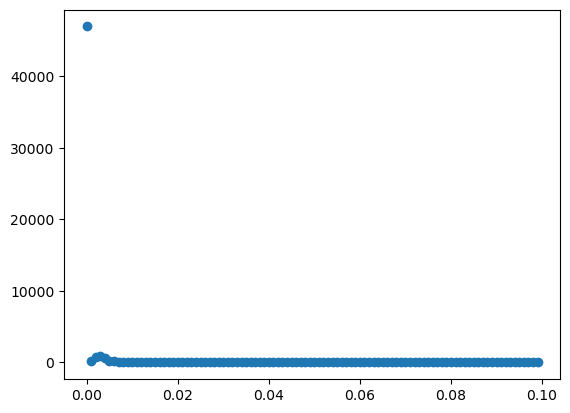

In [9]:
plt.scatter(Edep_0['Edep'][2:], Edep_0['Counts'][2:])

In [10]:
Edep_0['Counts']

0          0.000000
1          0.006006
2      46990.000000
3        162.100000
4        719.700000
           ...     
98         0.000000
99         0.000000
100        0.000000
101        0.000000
102             NaN
Name: Counts, Length: 103, dtype: float64

In [12]:
E_per_Q_room = 22.5 # the conversion factor from charge to energy in silicon at room temperature -- MeV/pC
phi = 200000 / ((1e-4)**2) # cm^-2

def cross_section(Qc, Edep, counts, phi, EpQ = E_per_Q_room):
    """
    Calculate the cross-section based on the given parameters.

    Parameters:
    Qc (float): Critical charge.
    Edep (float): Energy deposited in the material, MeV.
    counts (float): Number of detected events.
    phi (float): Fluence of the incident particles.
    EpQ (float): Conversion factor from charge to energy, MeV/pC.

    Returns:
    float: Calculated cross-section.
    """
    Ec = Qc * EpQ  # Critical energy
    N = 0
    for i in range(len(Edep)):
        E = Edep[i]
        if E >= Ec and (not np.isnan(E)):
            dN = counts[i]
            if np.isnan(dN):
                dN = 0
            N += dN    
    return N / phi

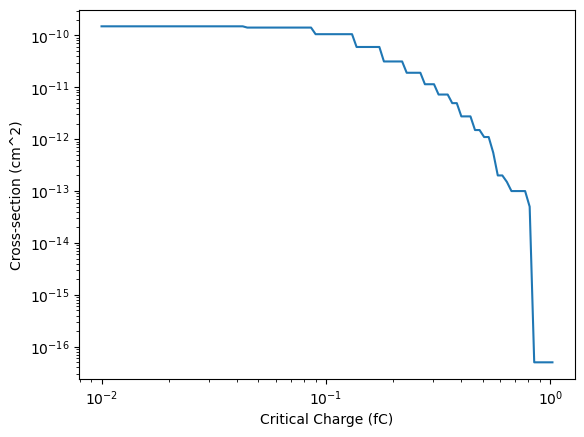

In [12]:
qs = np.logspace(-2, 0.01, 100)/1000
XSs = [cross_section(q, Edep_0['Edep'], Edep_0['Counts'], phi) for q in qs]

plt.plot(qs*1000, XSs)
plt.xlabel('Critical Charge (fC)')
plt.ylabel('Cross-section (cm^2)')
plt.xscale('log')
plt.yscale('log')
plt.show()

In [13]:
LET_HI1 = 5
LET_HI2 = 40.4

XS_HI1 = 2.57e-4
XS_HI2 = 4.61e-4

In [2]:
import numpy as np
np.sqrt(1e-9)

np.float64(3.1622776601683795e-05)

In [15]:
import shlex
import shutil
import subprocess
import sys
from pathlib import Path

G4SEE_CONTAINER_NAME = "g4see-notebook"
G4SEE_IMAGE = "gitlab-registry.cern.ch/g4see/g4see:v1.0_G4-11.2.2"
G4SEE_HOST_FOLDER = Path("D:/ProtonIrrad")


def start_g4see_container():
    """Start the G4SEE container with the project mounted at /home."""
    if shutil.which("docker") is None:
        raise RuntimeError("Docker CLI was not found. Install/start Docker Desktop and restart the notebook kernel.")
    if not G4SEE_HOST_FOLDER.is_dir():
        raise FileNotFoundError(f"Project folder does not exist: {G4SEE_HOST_FOLDER}")

    inspect = subprocess.run(
        ["docker", "inspect", "--format", "{{.State.Running}}", G4SEE_CONTAINER_NAME],
        capture_output=True,
        text=True,
    )
    if inspect.returncode == 0:
        if inspect.stdout.strip().lower() == "true":
            print(f"Container {G4SEE_CONTAINER_NAME!r} is already running.")
            return
        subprocess.run(["docker", "start", G4SEE_CONTAINER_NAME], check=True, text=True)
        print(f"Started existing container {G4SEE_CONTAINER_NAME!r}.")
        return

    mount = f"{G4SEE_HOST_FOLDER.resolve().as_posix()}:/home"
    subprocess.run(
        [
            "docker", "run", "--detach", "--name", G4SEE_CONTAINER_NAME,
            "--hostname", "g4see", "--volume", mount,
            G4SEE_IMAGE, "tail", "-f", "/dev/null",
        ],
        check=True,
        text=True,
    )
    print(f"Started {G4SEE_CONTAINER_NAME!r}; {G4SEE_HOST_FOLDER} is mounted at /home.")


def run_g4see_command(command):
    """Run a command in the container with the Geant4 environment loaded."""
    if isinstance(command, str):
        command_text = command
    else:
        command_text = shlex.join([str(part) for part in command])

    result = subprocess.run(
        [
            "docker", "exec", "--env", "SHELL=/bin/bash",
            "--workdir", "/home", G4SEE_CONTAINER_NAME,
            "bash", "-lc",
            "source /opt/geant4/install/bin/geant4.sh && export PATH=\"${G4SEE_BUILD}:$PATH\" && "
            f"{command_text}",
        ],
        capture_output=True,
        text=True,
    )
    if result.stdout:
        print(result.stdout, end="")
    if result.stderr:
        print(result.stderr, end="", file=sys.stderr)
    result.check_returncode()
    return result


def stop_g4see_container():
    """Stop the G4SEE container when finished."""
    return subprocess.run(["docker", "stop", G4SEE_CONTAINER_NAME], check=True, text=True)


if shutil.which("docker") is None:
    print("Docker CLI not found. Install/start Docker Desktop, then run start_g4see_container().")
else:
    start_g4see_container()

Started 'g4see-notebook'; D:\ProtonIrrad is mounted at /home.


In [14]:
def run_g4see_energy_sweep(
    energies,
    source_mac_path,
    output_folder,
    generated_mac_folder=None,
    energy_unit="MeV",
):
    """
    Run one G4SEE simulation per energy and return its Edep histogram.

    Numeric energies use ``energy_unit`` (MeV by default). String energies
    should include the unit, for example ``"20 MeV"``. Temporary simulation
    output files and generated macros are deleted after each histogram is read.
    The source macro is never modified or deleted.

    Parameters
    ----------
    energies : iterable
        Energy values, such as ``[10, 20, 30]`` or ``["10 MeV", "20 MeV"]``.
    source_mac_path : str or pathlib.Path
        Source ``.mac`` file, absolute or relative to ``G4SEE_HOST_FOLDER``.
    output_folder : str or pathlib.Path
        Base folder for temporary simulation output, absolute or relative to
        ``G4SEE_HOST_FOLDER``. It must be inside the Docker-mounted project.
    generated_mac_folder : str or pathlib.Path, optional
        Folder for temporary generated macros. Defaults to
        ``.g4see_generated_macros`` under the project folder.
    energy_unit : str, optional
        Unit appended to numeric energies. Defaults to ``"MeV"``.

    Returns
    -------
    dict[str, pandas.DataFrame]
        Edep histograms keyed by energy text, for example ``"20 MeV"``.
    """
    import re
    import tempfile

    energies = list(energies)
    if not energies:
        raise ValueError("energies must contain at least one value.")

    energy_texts = [
        f"{energy} {energy_unit}" if not isinstance(energy, str) else energy.strip()
        for energy in energies
    ]
    if any(not energy for energy in energy_texts):
        raise ValueError("Energy values cannot be empty.")
    if len(set(energy_texts)) != len(energy_texts):
        raise ValueError("Energy values must be unique.")

    project_root = G4SEE_HOST_FOLDER.resolve()

    def host_path(path):
        path = Path(path)
        if not path.is_absolute():
            path = project_root / path
        return path.resolve()

    def container_path(path):
        try:
            relative_path = host_path(path).relative_to(project_root)
        except ValueError as error:
            raise ValueError("Macro and output paths must be inside G4SEE_HOST_FOLDER.") from error
        return (Path("/home") / relative_path).as_posix()

    source_path = host_path(source_mac_path)
    if not source_path.is_file():
        raise FileNotFoundError(f"Source macro not found: {source_path}")

    if generated_mac_folder is None:
        generated_mac_folder = project_root / ".g4see_generated_macros"
    generated_folder = host_path(generated_mac_folder)
    base_output_folder = host_path(output_folder)

    container_path(source_path)
    container_path(generated_folder)
    container_path(base_output_folder)

    start_g4see_container()
    base_output_folder.mkdir(parents=True, exist_ok=True)
    histograms = {}

    with tempfile.TemporaryDirectory(
        prefix="g4see_energy_sweep_",
        dir=base_output_folder,
    ) as temporary_output:
        temporary_output = Path(temporary_output)

        for index, energy_text in enumerate(energy_texts, start=1):
            energy_label = re.sub(r"[^A-Za-z0-9_.-]+", "_", energy_text).strip("._-") or "energy"
            run_output_folder = temporary_output / f"run_{index:03d}_{energy_label}"
            run_output_folder.mkdir()

            generated_mac = None
            try:
                generated_mac = generate_mac_with_gps_energy(
                    source_path,
                    generated_folder,
                    energy_text,
                )
                container_mac = container_path(generated_mac)
                container_run_output = container_path(run_output_folder)
                print(f"Running G4SEE for {energy_text}...")
                run_g4see_command([
                    "g4see",
                    container_mac,
                    "-o",
                    container_run_output,
                ])

                histogram_path = run_output_folder / "Edep_0_hist_t0.out"
                if not histogram_path.is_file():
                    raise FileNotFoundError(
                        f"Expected histogram was not produced: {histogram_path}"
                    )
                histograms[energy_text] = read_hist_out(histogram_path)
            finally:
                if generated_mac is not None and generated_mac.exists():
                    generated_mac.unlink()

    return histograms

In [4]:
def run_g4see_cross_section_sweep(
    energies,
    Qc,
    phi,
    source_mac_path,
    output_folder,
    generated_mac_folder=None,
    energy_unit="MeV",
    EpQ=None,
):
    """
    Run a GPS-energy sweep and calculate the SEE cross-section at fixed Qc.

    Parameters
    ----------
    energies : iterable
        GPS energies, for example ``[10, 20, 30]`` (in MeV by default).
    Qc : float
        Fixed critical charge, in pC, used for every energy.
    phi : float
        Incident particle fluence.
    source_mac_path : str or pathlib.Path
        Source G4SEE macro file.
    output_folder : str or pathlib.Path
        Folder used for temporary simulation output; sweep outputs are deleted
        after their histograms are read.
    generated_mac_folder : str or pathlib.Path, optional
        Folder for temporary generated macros.
    energy_unit : str, optional
        Unit for numeric energies. Defaults to ``"MeV"``.
    EpQ : float, optional
        Charge-to-energy conversion factor. Defaults to ``E_per_Q_room``.

    Returns
    -------
    dict[str, float]
        SEE cross-sections keyed by GPS energy text, for example ``"20 MeV"``.
    """
    if EpQ is None:
        EpQ = E_per_Q_room

    histograms = run_g4see_energy_sweep(
        energies=energies,
        source_mac_path=source_mac_path,
        output_folder=output_folder,
        generated_mac_folder=generated_mac_folder,
        energy_unit=energy_unit,
    )

    return {
        energy: cross_section(
            Qc,
            histogram["Edep"],
            histogram["Counts"],
            phi,
            EpQ=EpQ,
        )
        for energy, histogram in histograms.items()
    }

In [8]:
def run_g4see_beol_thickness_sweep(
    energies,
    beol_thicknesses,
    Qc,
    phi,
    source_mac_path,
    output_folder,
    thickness_unit="um",
    generated_mac_folder=None,
    energy_unit="MeV",
    EpQ=None,
):
    """
    Calculate SEE cross-sections across GPS energies and first-BEOL thicknesses.

    For each thickness, a temporary copy of the source macro is created and
    only the THICK value on its first BEOL addLayer line is changed. Simulation
    outputs and temporary macros are removed after the cross-sections are read.
    The source macro remains unchanged.

    Parameters
    ----------
    energies : iterable
        GPS energy values; numeric values use ``energy_unit``.
    beol_thicknesses : iterable
        Numeric thickness values for the first BEOL layer.
    Qc : float
        Fixed critical charge in pC.
    phi : float
        Incident particle fluence.
    source_mac_path : str or pathlib.Path
        Source G4SEE macro, absolute or relative to ``G4SEE_HOST_FOLDER``.
    output_folder : str or pathlib.Path
        Parent folder for temporary simulation output, inside the mounted project.
    thickness_unit : str, optional
        Unit appended to all thickness values. Defaults to ``"um"``.
    generated_mac_folder : str or pathlib.Path, optional
        Folder for generated GPS-energy macros, passed to the energy sweep.
    energy_unit : str, optional
        Unit for numeric GPS energies. Defaults to ``"MeV"``.
    EpQ : float, optional
        Charge-to-energy conversion factor. Defaults to ``E_per_Q_room``.

    Returns
    -------
    dict[str, dict[str, float]]
        Cross-sections keyed first by BEOL thickness text and then by GPS energy,
        for example ``results["1.6 um"]["20 MeV"]``.
    """
    import re
    import shutil
    import tempfile
    from pathlib import Path

    thicknesses = list(beol_thicknesses)
    if not thicknesses:
        raise ValueError("beol_thicknesses must contain at least one value.")

    project_root = G4SEE_HOST_FOLDER.resolve()

    def project_path(path):
        path = Path(path)
        if not path.is_absolute():
            path = project_root / path
        path = path.resolve()
        try:
            path.relative_to(project_root)
        except ValueError as error:
            raise ValueError("Source and output paths must be inside G4SEE_HOST_FOLDER.") from error
        return path

    source_path = project_path(source_mac_path)
    if not source_path.is_file():
        raise FileNotFoundError(f"Source macro not found: {source_path}")

    first_layer = None
    with source_path.open("r") as source_file:
        for raw_line in source_file:
            command = raw_line.split("#", 1)[0].split()
            if command[:1] == ["/SEE/geometry/BEOL/addLayer"]:
                first_layer = command
                break

    if first_layer is None:
        raise ValueError(f"No '/SEE/geometry/BEOL/addLayer' line found in {source_path}.")
    if len(first_layer) < 8:
        raise ValueError(f"Unexpected first BEOL addLayer line format in {source_path}.")

    first_width, first_width_unit = first_layer[2], first_layer[3]
    base_output_folder = project_path(output_folder)
    base_output_folder.mkdir(parents=True, exist_ok=True)
    results = {}

    for thickness in thicknesses:
        thickness_key = f"{thickness} {thickness_unit}".strip()
        thickness_label = re.sub(r"[^A-Za-z0-9_.-]+", "_", thickness_key).strip("._-") or "thickness"
        if thickness_key in results:
            raise ValueError(f"Duplicate BEOL thickness: {thickness_key}")

        with tempfile.TemporaryDirectory(
            prefix=f".beol_macro_{thickness_label}_",
            dir=project_root,
        ) as temporary_macro_folder:
            temporary_macro = Path(temporary_macro_folder) / (
                f"{source_path.stem}_beol_{thickness_label}{source_path.suffix}"
            )
            shutil.copy2(source_path, temporary_macro)
            edit_first_beol_layer(
                temporary_macro,
                width=first_width,
                thick=thickness,
                width_unit=first_width_unit,
                thick_unit=thickness_unit,
            )

            with tempfile.TemporaryDirectory(
                prefix=f"beol_{thickness_label}_",
                dir=base_output_folder,
            ) as temporary_output_folder:
                print(f"Running energy sweep at first-BEOL thickness {thickness_key}...")
                results[thickness_key] = run_g4see_cross_section_sweep(
                    energies=energies,
                    Qc=Qc,
                    phi=phi,
                    source_mac_path=temporary_macro,
                    output_folder=temporary_output_folder,
                    generated_mac_folder=generated_mac_folder,
                    energy_unit=energy_unit,
                    EpQ=EpQ,
                )

    return results

In [6]:
def run_g4see_sv_thickness_sweep(
    energies,
    sv_thicknesses,
    beol_thicknesses,
    Qc,
    phi,
    source_mac_path,
    output_folder,
    sv_thickness_unit="nm",
    beol_thickness_unit="um",
    generated_mac_folder=None,
    energy_unit="MeV",
    EpQ=None,
):
    """
    Sweep SV and first-BEOL thicknesses, then return SEE cross-sections by energy.

    For each SV thickness, this makes a temporary source-macro copy and changes
    only the SV THICK field. It then calls ``run_g4see_beol_thickness_sweep``
    for the requested BEOL thicknesses and GPS energies. Temporary macros and
    simulation outputs are removed; the original source macro is unchanged.

    Parameters
    ----------
    energies : iterable
        GPS energy values; numeric values use ``energy_unit``.
    sv_thicknesses : iterable
        Numeric sensitive-volume thickness values.
    beol_thicknesses : iterable
        Numeric first-BEOL-layer thickness values.
    Qc : float
        Fixed critical charge in pC.
    phi : float
        Incident particle fluence.
    source_mac_path : str or pathlib.Path
        Source G4SEE macro, absolute or relative to ``G4SEE_HOST_FOLDER``.
    output_folder : str or pathlib.Path
        Parent folder for temporary simulation output, inside the mounted project.
    sv_thickness_unit : str, optional
        Unit for SV thickness values. Defaults to ``"nm"``.
    beol_thickness_unit : str, optional
        Unit for BEOL thickness values. Defaults to ``"um"``.
    generated_mac_folder : str or pathlib.Path, optional
        Folder for generated GPS-energy macros, passed to the existing sweep.
    energy_unit : str, optional
        Unit for numeric GPS energies. Defaults to ``"MeV"``.
    EpQ : float, optional
        Charge-to-energy conversion factor. Defaults to ``E_per_Q_room``.

    Returns
    -------
    dict[str, dict[str, dict[str, float]]]
        Results keyed by SV thickness, BEOL thickness, and energy, e.g.
        ``results["600 nm"]["1.6 um"]["20 MeV"]``.
    """
    import re
    import shutil
    import tempfile
    from pathlib import Path

    sv_thickness_values = list(sv_thicknesses)
    if not sv_thickness_values:
        raise ValueError("sv_thicknesses must contain at least one value.")

    project_root = G4SEE_HOST_FOLDER.resolve()

    def project_path(path):
        path = Path(path)
        if not path.is_absolute():
            path = project_root / path
        path = path.resolve()
        try:
            path.relative_to(project_root)
        except ValueError as error:
            raise ValueError("Source and output paths must be inside G4SEE_HOST_FOLDER.") from error
        return path

    source_path = project_path(source_mac_path)
    if not source_path.is_file():
        raise FileNotFoundError(f"Source macro not found: {source_path}")

    sv_tokens = None
    with source_path.open("r") as source_file:
        for raw_line in source_file:
            tokens = raw_line.split("#", 1)[0].split()
            if tokens[:1] == ["/SEE/geometry/SV"]:
                sv_tokens = tokens
                break

    if sv_tokens is None:
        raise ValueError(f"No '/SEE/geometry/SV' line found in {source_path}.")
    if len(sv_tokens) < 11:
        raise ValueError(f"Unexpected SV line format in {source_path}.")

    sv_width = (sv_tokens[5], sv_tokens[6])
    sv_width_unit = sv_tokens[7]
    base_output_folder = project_path(output_folder)
    base_output_folder.mkdir(parents=True, exist_ok=True)
    results = {}

    for sv_thickness in sv_thickness_values:
        sv_key = f"{sv_thickness} {sv_thickness_unit}".strip()
        sv_label = re.sub(r"[^A-Za-z0-9_.-]+", "_", sv_key).strip("._-") or "thickness"
        if sv_key in results:
            raise ValueError(f"Duplicate SV thickness: {sv_key}")

        with tempfile.TemporaryDirectory(
            prefix=f".sv_macro_{sv_label}_",
            dir=project_root,
        ) as temporary_macro_folder:
            temporary_macro = Path(temporary_macro_folder) / (
                f"{source_path.stem}_sv_{sv_label}{source_path.suffix}"
            )
            shutil.copy2(source_path, temporary_macro)
            edit_sv_geometry(
                temporary_macro,
                width=sv_width,
                thick=sv_thickness,
                width_unit=sv_width_unit,
                thick_unit=sv_thickness_unit,
            )

            with tempfile.TemporaryDirectory(
                prefix=f"sv_{sv_label}_",
                dir=base_output_folder,
            ) as temporary_output_folder:
                print(f"Running BEOL and energy sweeps at SV thickness {sv_key}...")
                results[sv_key] = run_g4see_beol_thickness_sweep(
                    energies=energies,
                    beol_thicknesses=beol_thicknesses,
                    Qc=Qc,
                    phi=phi,
                    source_mac_path=temporary_macro,
                    output_folder=temporary_output_folder,
                    thickness_unit=beol_thickness_unit,
                    generated_mac_folder=generated_mac_folder,
                    energy_unit=energy_unit,
                    EpQ=EpQ,
                )

    return results

In [10]:
def run_g4see_sv_beol_qc_sweep(
    energies,
    sv_thicknesses,
    beol_thicknesses,
    critical_charges,
    phi,
    source_mac_path,
    output_folder,
    sv_thickness_unit="nm",
    beol_thickness_unit="um",
    generated_mac_folder=None,
    energy_unit="MeV",
    EpQ=None,
):
    """
    Sweep SV thickness, first-BEOL thickness, GPS energy, and critical charge.

    Each geometry/energy simulation is run once. Its Edep histogram is then
    reused to calculate cross-sections for every requested critical charge.
    Temporary macros and simulation outputs are removed, and the source macro
    is not modified.

    Parameters
    ----------
    energies : iterable
        GPS energy values; numeric values use ``energy_unit``.
    sv_thicknesses : iterable
        Numeric sensitive-volume thickness values.
    beol_thicknesses : iterable
        Numeric first-BEOL-layer thickness values.
    critical_charges : iterable
        Critical charges in pC, evaluated against each simulation histogram.
    phi : float
        Incident particle fluence.
    source_mac_path : str or pathlib.Path
        Source G4SEE macro, absolute or relative to ``G4SEE_HOST_FOLDER``.
    output_folder : str or pathlib.Path
        Parent folder for temporary simulation output, inside the mounted project.
    sv_thickness_unit : str, optional
        Unit for SV thickness values. Defaults to ``"nm"``.
    beol_thickness_unit : str, optional
        Unit for BEOL thickness values. Defaults to ``"um"``.
    generated_mac_folder : str or pathlib.Path, optional
        Folder for generated GPS-energy macros, passed to the energy sweep.
    energy_unit : str, optional
        Unit for numeric GPS energies. Defaults to ``"MeV"``.
    EpQ : float, optional
        Charge-to-energy conversion factor. Defaults to ``E_per_Q_room``.

    Returns
    -------
    dict[str, dict[str, dict[str, dict[float, float]]]]
        Results keyed as SV thickness -> BEOL thickness -> energy -> Qc, e.g.
        ``results["600 nm"]["1.6 um"]["20 MeV"][0.01]``.
    """
    import re
    import shutil
    import tempfile
    from pathlib import Path

    sv_thickness_values = list(sv_thicknesses)
    beol_thickness_values = list(beol_thicknesses)
    critical_charge_values = list(critical_charges)
    if not sv_thickness_values:
        raise ValueError("sv_thicknesses must contain at least one value.")
    if not beol_thickness_values:
        raise ValueError("beol_thicknesses must contain at least one value.")
    if not critical_charge_values:
        raise ValueError("critical_charges must contain at least one value.")
    if len(set(critical_charge_values)) != len(critical_charge_values):
        raise ValueError("critical_charges must be unique.")

    project_root = G4SEE_HOST_FOLDER.resolve()

    def project_path(path):
        path = Path(path)
        if not path.is_absolute():
            path = project_root / path
        path = path.resolve()
        try:
            path.relative_to(project_root)
        except ValueError as error:
            raise ValueError("Source and output paths must be inside G4SEE_HOST_FOLDER.") from error
        return path

    source_path = project_path(source_mac_path)
    if not source_path.is_file():
        raise FileNotFoundError(f"Source macro not found: {source_path}")

    sv_tokens = None
    first_beol_layer = None
    with source_path.open("r") as source_file:
        for raw_line in source_file:
            tokens = raw_line.split("#", 1)[0].split()
            if sv_tokens is None and tokens[:1] == ["/SEE/geometry/SV"]:
                sv_tokens = tokens
            if first_beol_layer is None and tokens[:1] == ["/SEE/geometry/BEOL/addLayer"]:
                first_beol_layer = tokens
            if sv_tokens is not None and first_beol_layer is not None:
                break

    if sv_tokens is None:
        raise ValueError(f"No '/SEE/geometry/SV' line found in {source_path}.")
    if len(sv_tokens) < 11:
        raise ValueError(f"Unexpected SV line format in {source_path}.")
    if first_beol_layer is None:
        raise ValueError(f"No '/SEE/geometry/BEOL/addLayer' line found in {source_path}.")
    if len(first_beol_layer) < 8:
        raise ValueError(f"Unexpected first BEOL addLayer line format in {source_path}.")

    sv_width = (sv_tokens[5], sv_tokens[6])
    sv_width_unit = sv_tokens[7]
    beol_width = first_beol_layer[2]
    beol_width_unit = first_beol_layer[3]
    base_output_folder = project_path(output_folder)
    base_output_folder.mkdir(parents=True, exist_ok=True)
    results = {}

    for sv_thickness in sv_thickness_values:
        sv_key = f"{sv_thickness} {sv_thickness_unit}".strip()
        sv_label = re.sub(r"[^A-Za-z0-9_.-]+", "_", sv_key).strip("._-") or "thickness"
        if sv_key in results:
            raise ValueError(f"Duplicate SV thickness: {sv_key}")
        results[sv_key] = {}

        with tempfile.TemporaryDirectory(
            prefix=f".sv_qc_macro_{sv_label}_",
            dir=project_root,
        ) as sv_macro_folder:
            sv_macro = Path(sv_macro_folder) / f"{source_path.stem}_sv_{sv_label}{source_path.suffix}"
            shutil.copy2(source_path, sv_macro)
            edit_sv_geometry(
                sv_macro,
                width=sv_width,
                thick=sv_thickness,
                width_unit=sv_width_unit,
                thick_unit=sv_thickness_unit,
            )

            for beol_thickness in beol_thickness_values:
                beol_key = f"{beol_thickness} {beol_thickness_unit}".strip()
                beol_label = re.sub(r"[^A-Za-z0-9_.-]+", "_", beol_key).strip("._-") or "thickness"
                if beol_key in results[sv_key]:
                    raise ValueError(f"Duplicate BEOL thickness: {beol_key}")

                with tempfile.TemporaryDirectory(
                    prefix=f".beol_qc_macro_{beol_label}_",
                    dir=project_root,
                ) as beol_macro_folder:
                    beol_macro = Path(beol_macro_folder) / (
                        f"{source_path.stem}_sv_{sv_label}_beol_{beol_label}{source_path.suffix}"
                    )
                    shutil.copy2(sv_macro, beol_macro)
                    edit_first_beol_layer(
                        beol_macro,
                        width=beol_width,
                        thick=beol_thickness,
                        width_unit=beol_width_unit,
                        thick_unit=beol_thickness_unit,
                    )

                    with tempfile.TemporaryDirectory(
                        prefix=f"sv_{sv_label}_beol_{beol_label}_",
                        dir=base_output_folder,
                    ) as temporary_output_folder:
                        print(f"Running simulations for SV {sv_key}, BEOL {beol_key}...")
                        histograms = run_g4see_energy_sweep(
                            energies=energies,
                            source_mac_path=beol_macro,
                            output_folder=temporary_output_folder,
                            generated_mac_folder=generated_mac_folder,
                            energy_unit=energy_unit,
                        )

                    results[sv_key][beol_key] = {
                        energy: {
                            Qc: cross_section(
                                Qc,
                                histogram["Edep"],
                                histogram["Counts"],
                                phi,
                                EpQ=E_per_Q_room if EpQ is None else EpQ,
                            )
                            for Qc in critical_charge_values
                        }
                        for energy, histogram in histograms.items()
                    }

    return results

In [16]:
def run_g4see_sv_beol_histogram_sweep(
    energies,
    sv_thicknesses,
    beol_thicknesses,
    source_mac_path,
    output_folder,
    sv_thickness_unit="nm",
    beol_thickness_unit="um",
    generated_mac_folder=None,
    energy_unit="MeV",
):
    """
    Return Edep histograms for every SV thickness, BEOL thickness, and energy.

    Each geometry/energy combination is simulated once. Histograms are read
    before temporary simulation outputs are removed. Temporary macro copies
    are also removed, and the source macro is never modified.

    Parameters
    ----------
    energies : iterable
        GPS energy values; numeric values use ``energy_unit``.
    sv_thicknesses : iterable
        Numeric sensitive-volume thickness values.
    beol_thicknesses : iterable
        Numeric first-BEOL-layer thickness values.
    source_mac_path : str or pathlib.Path
        Source G4SEE macro, absolute or relative to ``G4SEE_HOST_FOLDER``.
    output_folder : str or pathlib.Path
        Parent folder for temporary simulation output, inside the mounted project.
    sv_thickness_unit : str, optional
        Unit for SV thickness values. Defaults to ``"nm"``.
    beol_thickness_unit : str, optional
        Unit for BEOL thickness values. Defaults to ``"um"``.
    generated_mac_folder : str or pathlib.Path, optional
        Folder for generated GPS-energy macros, passed to the energy sweep.
    energy_unit : str, optional
        Unit for numeric GPS energies. Defaults to ``"MeV"``.

    Returns
    -------
    dict[str, dict[str, dict[str, pandas.DataFrame]]]
        Histograms keyed as SV thickness -> BEOL thickness -> energy, e.g.
        ``results["600 nm"]["1.6 um"]["20 MeV"]``.
    """
    import re
    import shutil
    import tempfile
    from pathlib import Path

    sv_thickness_values = list(sv_thicknesses)
    beol_thickness_values = list(beol_thicknesses)
    if not sv_thickness_values:
        raise ValueError("sv_thicknesses must contain at least one value.")
    if not beol_thickness_values:
        raise ValueError("beol_thicknesses must contain at least one value.")

    project_root = G4SEE_HOST_FOLDER.resolve()

    def project_path(path):
        path = Path(path)
        if not path.is_absolute():
            path = project_root / path
        path = path.resolve()
        try:
            path.relative_to(project_root)
        except ValueError as error:
            raise ValueError("Source and output paths must be inside G4SEE_HOST_FOLDER.") from error
        return path

    source_path = project_path(source_mac_path)
    if not source_path.is_file():
        raise FileNotFoundError(f"Source macro not found: {source_path}")

    sv_tokens = None
    first_beol_layer = None
    with source_path.open("r") as source_file:
        for raw_line in source_file:
            tokens = raw_line.split("#", 1)[0].split()
            if sv_tokens is None and tokens[:1] == ["/SEE/geometry/SV"]:
                sv_tokens = tokens
            if first_beol_layer is None and tokens[:1] == ["/SEE/geometry/BEOL/addLayer"]:
                first_beol_layer = tokens
            if sv_tokens is not None and first_beol_layer is not None:
                break

    if sv_tokens is None:
        raise ValueError(f"No '/SEE/geometry/SV' line found in {source_path}.")
    if len(sv_tokens) < 11:
        raise ValueError(f"Unexpected SV line format in {source_path}.")
    if first_beol_layer is None:
        raise ValueError(f"No '/SEE/geometry/BEOL/addLayer' line found in {source_path}.")
    if len(first_beol_layer) < 8:
        raise ValueError(f"Unexpected first BEOL addLayer line format in {source_path}.")

    sv_width = (sv_tokens[5], sv_tokens[6])
    sv_width_unit = sv_tokens[7]
    beol_width = first_beol_layer[2]
    beol_width_unit = first_beol_layer[3]
    base_output_folder = project_path(output_folder)
    base_output_folder.mkdir(parents=True, exist_ok=True)
    results = {}

    for sv_thickness in sv_thickness_values:
        sv_key = f"{sv_thickness} {sv_thickness_unit}".strip()
        sv_label = re.sub(r"[^A-Za-z0-9_.-]+", "_", sv_key).strip("._-") or "thickness"
        if sv_key in results:
            raise ValueError(f"Duplicate SV thickness: {sv_key}")
        results[sv_key] = {}

        with tempfile.TemporaryDirectory(
            prefix=f".sv_hist_macro_{sv_label}_",
            dir=project_root,
        ) as sv_macro_folder:
            sv_macro = Path(sv_macro_folder) / f"{source_path.stem}_sv_{sv_label}{source_path.suffix}"
            shutil.copy2(source_path, sv_macro)
            edit_sv_geometry(
                sv_macro,
                width=sv_width,
                thick=sv_thickness,
                width_unit=sv_width_unit,
                thick_unit=sv_thickness_unit,
            )

            for beol_thickness in beol_thickness_values:
                beol_key = f"{beol_thickness} {beol_thickness_unit}".strip()
                beol_label = re.sub(r"[^A-Za-z0-9_.-]+", "_", beol_key).strip("._-") or "thickness"
                if beol_key in results[sv_key]:
                    raise ValueError(f"Duplicate BEOL thickness: {beol_key}")

                with tempfile.TemporaryDirectory(
                    prefix=f".beol_hist_macro_{beol_label}_",
                    dir=project_root,
                ) as beol_macro_folder:
                    beol_macro = Path(beol_macro_folder) / (
                        f"{source_path.stem}_sv_{sv_label}_beol_{beol_label}{source_path.suffix}"
                    )
                    shutil.copy2(sv_macro, beol_macro)
                    edit_first_beol_layer(
                        beol_macro,
                        width=beol_width,
                        thick=beol_thickness,
                        width_unit=beol_width_unit,
                        thick_unit=beol_thickness_unit,
                    )

                    with tempfile.TemporaryDirectory(
                        prefix=f"sv_{sv_label}_beol_{beol_label}_",
                        dir=base_output_folder,
                    ) as temporary_output_folder:
                        print(f"Collecting histograms for SV {sv_key}, BEOL {beol_key}...")
                        results[sv_key][beol_key] = run_g4see_energy_sweep(
                            energies=energies,
                            source_mac_path=beol_macro,
                            output_folder=temporary_output_folder,
                            generated_mac_folder=generated_mac_folder,
                            energy_unit=energy_unit,
                        )

    return results

In [18]:
qs = np.logspace(-2, 0.01, 100)/1000
ret1 =run_g4see_cross_section_sweep(
        energies=[10, 30],
        Qc=qs[0],
        phi=phi,
        source_mac_path="D:/ProtonIrrad/G4SEE_input_files/examples/SRAM_temp.mac",
        output_folder="D:/ProtonIrrad/G4SEE_input_files/examples/g4see_energy_sweep_output",
    )

Container 'g4see-notebook' is already running.
Running G4SEE for 10 MeV...

**************************************************************
 Geant4 version Name: geant4-11-02-patch-02 [MT]   (21-June-2024)
                       Copyright : Geant4 Collaboration
                      References : NIM A 506 (2003), 250-303
                                 : IEEE-TNS 53 (2006), 270-278
                                 : NIM A 835 (2016), 186-225
                             WWW : http://geant4.org/
**************************************************************

Default random seeds: 2452282, 1163112070
which will be overwritten by macro command:  /random/setSeeds  iiii, jjjj

G4SEE path:        /home/g4see
Input macro file:  /home/.g4see_generated_macros/SRAM_temp_gps_ene_10_MeV.mac
Output directory:  /home/G4SEE_input_files/examples/g4see_energy_sweep_output/g4see_energy_sweep_o2rj6b77/run_001_10_MeV

PhysicsList::ConstructParticle
Visualization Manager instantiating with verbosity "warni

In [19]:
ret1

{'10 MeV': np.float64(1.5167425000000004e-10),
 '30 MeV': np.float64(1.1185055035000001e-10)}

In [20]:
energies = [10, 30]
ret = run_g4see_energy_sweep(
    energies,
    source_mac_path="D:/ProtonIrrad/G4SEE_input_files/examples/SRAM_temp.mac",
    output_folder="D:/ProtonIrrad/G4SEE_input_files/examples/g4see_energy_sweep_output",
)

Container 'g4see-notebook' is already running.
Running G4SEE for 10 MeV...

**************************************************************
 Geant4 version Name: geant4-11-02-patch-02 [MT]   (21-June-2024)
                       Copyright : Geant4 Collaboration
                      References : NIM A 506 (2003), 250-303
                                 : IEEE-TNS 53 (2006), 270-278
                                 : NIM A 835 (2016), 186-225
                             WWW : http://geant4.org/
**************************************************************

Default random seeds: 485770957, 1051338366
which will be overwritten by macro command:  /random/setSeeds  iiii, jjjj

G4SEE path:        /home/g4see
Input macro file:  /home/.g4see_generated_macros/SRAM_temp_gps_ene_10_MeV.mac
Output directory:  /home/G4SEE_input_files/examples/g4see_energy_sweep_output/g4see_energy_sweep_fylwi_ml/run_001_10_MeV

PhysicsList::ConstructParticle
Visualization Manager instantiating with verbosity "war

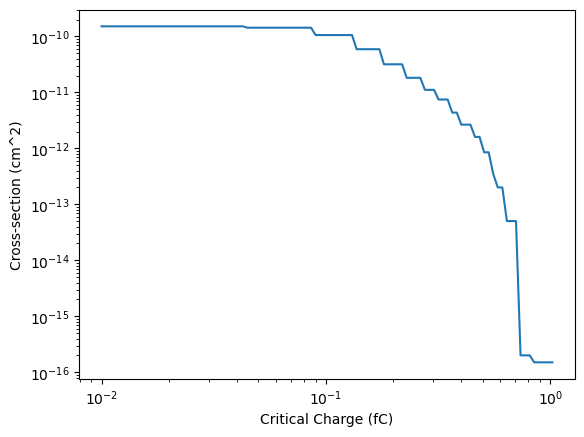

In [21]:

XSs = [cross_section(q, ret['10 MeV']['Edep'], ret['10 MeV']['Counts'], phi) for q in qs]

plt.plot(qs*1000, XSs)
plt.xlabel('Critical Charge (fC)')
plt.ylabel('Cross-section (cm^2)')
plt.xscale('log')
plt.yscale('log')
plt.show()

In [22]:
cross_section(qs[0], ret['10 MeV']['Edep'], ret['10 MeV']['Counts'], phi)

np.float64(1.5148185030000005e-10)

In [23]:
cross_section(qs[0], ret['30 MeV']['Edep'], ret['30 MeV']['Counts'], phi)

np.float64(1.0910020040000002e-10)

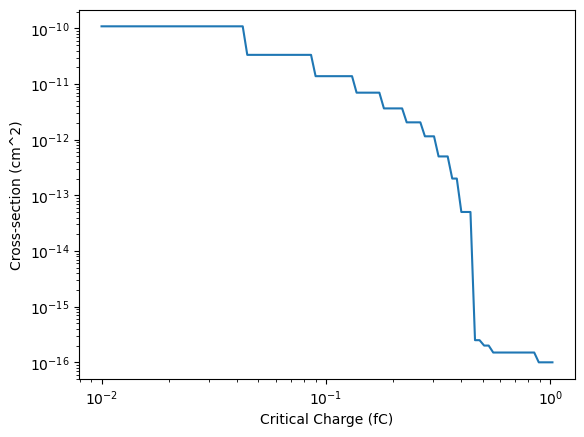

In [24]:
qs = np.logspace(-2, 0.01, 100)/1000
XSs = [cross_section(q, ret['30 MeV']['Edep'], ret['30 MeV']['Counts'], phi) for q in qs]

plt.plot(qs*1000, XSs)
plt.xlabel('Critical Charge (fC)')
plt.ylabel('Cross-section (cm^2)')
plt.xscale('log')
plt.yscale('log')
plt.show()

In [25]:
input_folder = "G4SEE_input_files/examples/"
input_max = "SRAM_temp.mac"

output_folder = "G4SEE_output_files/examples/SRAM/"

def run_g4see_simulation(input_folder, input_mac, output_folder):
    """
    Run a G4SEE simulation using the specified input macro file.

    Parameters
    ----------
    input_folder : str
        Path to the folder containing the input macro file.
    input_mac : str
        Name of the input macro file (e.g., "SRAM.mac").
    output_folder : str
        Path to the folder where output files will be saved.

    Returns
    -------
    None
    """
    input_path = input_folder + input_mac

    output_path = output_folder

    command = f"g4see {input_path} -o {output_path}"
    print(f"Running G4SEE simulation with command: {command}")
    run_g4see_command(command)
run_g4see_simulation(input_folder, input_max, output_folder)

Running G4SEE simulation with command: g4see G4SEE_input_files/examples/SRAM_temp.mac -o G4SEE_output_files/examples/SRAM/

**************************************************************
 Geant4 version Name: geant4-11-02-patch-02 [MT]   (21-June-2024)
                       Copyright : Geant4 Collaboration
                      References : NIM A 506 (2003), 250-303
                                 : IEEE-TNS 53 (2006), 270-278
                                 : NIM A 835 (2016), 186-225
                             WWW : http://geant4.org/
**************************************************************

Default random seeds: 277828175, 457846407
which will be overwritten by macro command:  /random/setSeeds  iiii, jjjj

G4SEE path:        /home/g4see
Input macro file:  /home/G4SEE_input_files/examples/SRAM_temp.mac
Output directory:  /home/G4SEE_output_files/examples/SRAM

PhysicsList::ConstructParticle
Visualization Manager instantiating with verbosity "warnings (3)"...
Visualization 

In [26]:
stop_g4see_container()

CompletedProcess(args=['docker', 'stop', 'g4see-notebook'], returncode=0)